# 模型量化：从 FP32 到 INT8

这个练习接在课程 2.2 的训练与评估、3.2 的 ONNX 推理之后。我们用离线自带的 digits 数据训练一个小型多层感知机（MLP），导出 FP32 ONNX，再分别做动态和静态 INT8 量化。

按顺序观察：数值怎样近似 → 权重是否真的变成 INT8 → 输入输出是否变化 → 文件缩小多少 → 准确率与错误案例怎样变化 → 当前 CPU 上是否更快。

量化是一种用更少位数表示数值的模型优化方法。它通常会引入近似误差，不能预先保证速度或准确率一定改善。


## 1. 位宽、scale 与 zero point

FP32 每个数占 32 位（4 字节），INT8 每个数占 8 位（1 字节）。同样数量的纯权重从 FP32 改为 INT8，理论存储约为原来的四分之一；完整文件还包括计算图、偏置、缩放参数和未量化部分，所以不一定恰好缩小四倍。文件大小也不等于运行时峰值内存。

常见线性量化可理解为：

$$q = \operatorname{clip}(\operatorname{round}(x/s) + z, q_{\min}, q_{\max})$$
$$\hat{x} = s(q-z)$$

其中 x 是原数值，q 是整数表示，s 是正缩放因子，z 是零点，恢复值不一定等于原值。clip 防止超出整数范围。下面手算采用对称区间 [-127,127]、z=0、s=max(abs(x))/127；它只是帮助理解的一个方案，并不复刻 ONNX Runtime 内部全部量化策略。舍入、缩放和饱和规则可对照 [ONNX QuantizeLinear](https://onnx.ai/onnx/operators/onnx__QuantizeLinear.html)。


In [1]:
import json
import platform
import sys
from hashlib import sha256
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from skl2onnx import to_onnx
from onnxruntime.quantization import (
    CalibrationDataReader, CalibrationMethod, QuantFormat, QuantType,
    quantize_dynamic, quantize_static,
)
from onnxruntime.quantization.shape_inference import quant_pre_process

from lesson_utils import benchmark_sessions, compare_predictions, model_summary, symmetric_int8

packages = ["numpy", "scikit-learn", "scipy", "onnx", "onnxruntime", "skl2onnx"]
print(sys.version.split()[0], platform.machine(), platform.platform())
print({name: version(name) for name in packages})
print("可用后端:", ort.get_available_providers())
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


3.12.14 arm64 macOS-26.7.1-arm64-arm-64bit
{'numpy': '2.2.6', 'scikit-learn': '1.8.0', 'scipy': '1.18.1', 'onnx': '1.19.1', 'onnxruntime': '1.23.2', 'skl2onnx': '1.20.0'}
可用后端: ['CoreMLExecutionProvider', 'AzureExecutionProvider', 'CPUExecutionProvider']


In [2]:
values = np.array([-1.0, -0.5, 0.0, 0.25, 0.9, 1.0], dtype=np.float32)
q, scale, restored = symmetric_int8(values)
print("scale =", scale, "; zero_point = 0")
display(pd.DataFrame({
    "原值": values,
    "INT8": q,
    "恢复值": restored,
    "绝对误差": np.abs(values - restored),
}))


scale = 0.007874015748031496 ; zero_point = 0


,原值,INT8,恢复值,绝对误差
0,-1.00,-127,-1.000000,0.000000
1,-0.50,-64,-0.503937,0.003937
2,0.00,0,0.000000,0.000000
3,0.25,32,0.251969,0.001969
4,0.90,114,0.897638,0.002362
5,1.00,127,1.000000,0.000000


观察 -0.5、0.25 等值：有限的整数刻度不能表达所有原始小数，舍入后会有误差。本例恢复值仍是浮点数，但已不能找回舍入丢失的信息。

把数组直接 astype(np.int8) 只是类型转换，会截断小数等，不会自动计算 scale 和 zero point；修改输入图片的 dtype 也不等于量化模型权重。

## 2. 动态、静态与量化感知训练

PTQ 全称 Post-Training Quantization，训练后量化；QAT 全称 Quantization-Aware Training，量化感知训练。

| 方法 | 权重与激活范围怎样确定 | 是否需要代表性样本 | 是否重新训练 |
|---|---|---|---|
| 训练后动态量化（PTQ） | 权重预先量化，部分激活的量化参数在推理时计算 | 不需要离线校准集 | 不更新已有模型参数 |
| 训练后静态量化（PTQ） | 用样本运行原模型，预先确定激活范围 | 需要校准输入，通常不需要标签 | 不做梯度训练 |
| 量化感知训练（QAT） | 训练时模拟舍入和截断等误差，让参数适应 | 需要训练数据和训练流程 | 会更新可训练参数 |

权重是模型学到的参数，激活是输入经过各层计算得到的中间数值。动态量化不是每次请求重新训练；静态量化的校准也不是拿标签计算梯度。QAT 通常仍用浮点参数配合模拟量化，不是简单地用 INT8 参数直接反向传播。本练习实际执行前两种 PTQ。方法说明见 [ONNX Runtime](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html)，训练时模拟量化的原始研究见 [Jacob 等人的论文](https://arxiv.org/abs/1712.05877)。


## 3. 准备小模型与保留测试集

digits 是 scikit-learn 自带的 8×8 灰度数字数据，共 1797 个样本、10 类。它不是课程 3.2.2 使用的 28×28 MNIST，也不能直接拿来喂给那个 mnist.onnx。

每张图展开为 64 个特征，像素原范围为 0–16，固定除以 16 映射到 [0,1]，不需要从全量数据估计缩放统计量。训练/测试按 8:2 分层划分；方法与参数预先固定，不根据下面测试结果继续调参。


训练: (1437, 64) 测试: (360, 64) 输入类型: float32


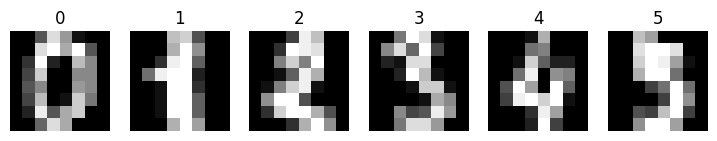

In [3]:
digits = load_digits()
X = np.ascontiguousarray(digits.data / 16, dtype=np.float32)
y = digits.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("训练:", X_train.shape, "测试:", X_test.shape, "输入类型:", X.dtype)

fig, axes = plt.subplots(1, 6, figsize=(9, 2))
for ax, image, label in zip(axes, digits.images[:6], y[:6]):
    ax.imshow(image, cmap="gray")
    ax.set_title(str(label))
    ax.axis("off")
plt.show()


In [4]:
model = MLPClassifier(
    hidden_layer_sizes=(64,),
    activation="relu",
    solver="lbfgs",
    max_iter=400,
    random_state=42,
)
model.fit(X_train, y_train)
print("网络: 64 个输入 → 64 个隐藏单元 → 10 个类别")
print("权重形状:", [weight.shape for weight in model.coefs_])
print("训练优化迭代次数:", model.n_iter_)
assert np.array_equal(model.classes_, np.arange(10))


网络: 64 个输入 → 64 个隐藏单元 → 10 个类别
权重形状: [(64, 64), (64, 10)]
训练优化迭代次数: 59


这里的训练用于生成一个独立、可复现的小模型。后面的量化对已经训练好的模型做转换，训练、导出与量化是三个不同步骤。

## 4. 导出并验证 FP32 ONNX

skl2onnx 负责模型转换。关闭 ZipMap，输出直接使用 (N,10) 概率矩阵；该分类器导出时已经带 Softmax，不再额外套一次。类别顺序来自 model.classes_，本例恰好是 0–9。

quant_pre_process 用于量化前的模型形状处理。本例关闭这一阶段的图融合，保留易观察的 MatMul；实际推理时三个模型使用相同的运行时图优化设置。先验证导出正确，之后的差异才适合归因于量化。


In [5]:
raw_path = OUTPUT_DIR / "digits_export.onnx"
fp32_path = OUTPUT_DIR / "digits_fp32.onnx"
exported = to_onnx(
    model, X_train[:1], options={id(model): {"zipmap": False}},
    target_opset=17,
)
raw_path.write_bytes(exported.SerializeToString())
quant_pre_process(
    str(raw_path), str(fp32_path),
    skip_optimization=True, skip_symbolic_shape=True,
)
original_hash = sha256(fp32_path.read_bytes()).hexdigest()

def create_session(path):
    options = ort.SessionOptions()
    options.intra_op_num_threads = 1
    options.inter_op_num_threads = 1
    options.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL
    return ort.InferenceSession(
        str(path), sess_options=options, providers=["CPUExecutionProvider"]
    )

fp32_session = create_session(fp32_path)
input_name = fp32_session.get_inputs()[0].name
probability_name = next(
    output.name for output in fp32_session.get_outputs()
    if len(output.shape) == 2 and output.shape[1] == 10
)
print("输入:", [(p.name, p.shape, p.type) for p in fp32_session.get_inputs()])
print("输出:", [(p.name, p.shape, p.type) for p in fp32_session.get_outputs()])

def predict_probabilities(session, samples, batch_size=64):
    return np.concatenate([
        session.run(
            [probability_name],
            {input_name: np.ascontiguousarray(samples[i:i + batch_size])},
        )[0]
        for i in range(0, len(samples), batch_size)
    ])

fp32_probabilities = predict_probabilities(fp32_session, X_test)
np.testing.assert_allclose(
    fp32_probabilities, model.predict_proba(X_test), rtol=1e-4, atol=1e-5
)
print("FP32 ONNX 与 scikit-learn 的概率输出接近：通过")


输入: [('X', [None, 64], 'tensor(float)')]
输出: [('label', ['unk__1'], 'tensor(int64)'), ('probabilities', ['unk__0', 10], 'tensor(float)')]
FP32 ONNX 与 scikit-learn 的概率输出接近：通过


## 5. 动态 INT8 量化

quantize_dynamic 读取 FP32 文件，写出另一个文件。weight_type 指定权重整数类型，op_types_to_quantize 限定本例量化矩阵乘法；per_channel=True 为权重按通道确定缩放参数，避免所有通道必须共用一个范围。

动态量化的激活范围在推理时根据实际数据计算，所以同一样本与不同样本一起组成 batch 时，结果可能略有差异。后面准确率比较统一使用 batch_size=64。


In [6]:
dynamic_path = OUTPUT_DIR / "digits_dynamic_int8.onnx"
quantize_dynamic(
    str(fp32_path), str(dynamic_path),
    weight_type=QuantType.QInt8,
    op_types_to_quantize=["MatMul"],
    per_channel=True,
)
print("动态量化完成:", dynamic_path.name)


动态量化完成: digits_dynamic_int8.onnx


## 6. 静态 INT8 量化与校准

校准输入应代表部署时的尺寸、类型、数值范围和常见场景。这里只取训练部分的前 128 个输入，分成每批 16 个；不使用测试样本或标签。MinMax 校准估计激活范围，不是前面把像素除以 16，也不是 sklearn 的 MinMaxScaler。

QDQ 图会插入 QuantizeLinear / DequantizeLinear 来表达量化边界。权重选 INT8，激活选 UINT8；两者同为 8 位，但整数范围不同。部分算子与输入输出仍是浮点数，不能把“INT8 模型”理解成图中每个数都是 INT8。


In [7]:
calibration_inputs = X_train[:128]

class DigitsCalibrationReader(CalibrationDataReader):
    def __init__(self, samples):
        self.batches = iter([
            {input_name: np.ascontiguousarray(samples[i:i + 16])}
            for i in range(0, len(samples), 16)
        ])

    def get_next(self):
        return next(self.batches, None)

static_path = OUTPUT_DIR / "digits_static_int8.onnx"
quantize_static(
    str(fp32_path), str(static_path),
    DigitsCalibrationReader(calibration_inputs),
    quant_format=QuantFormat.QDQ,
    activation_type=QuantType.QUInt8,
    weight_type=QuantType.QInt8,
    op_types_to_quantize=["MatMul"],
    calibrate_method=CalibrationMethod.MinMax,
    per_channel=True,
)
print("校准输入数:", len(calibration_inputs))
print("静态量化完成:", static_path.name)


校准输入数: 128
静态量化完成: digits_static_int8.onnx


## 7. 检查文件、权重类型与预测质量

不能只改文件名为 int8 就称量化成功。检查图中的实际权重类型与算子，同时确认原 FP32 文件没有被覆盖。

准确率比较预测与真实标签；预测一致率比较量化前后两组预测，二者不等价。量化前后准确率一样时，仍可能有一部分“原本正确变错误”和另一部分“原本错误变正确”相互抵消。


In [8]:
paths = {"FP32": fp32_path, "Dynamic INT8": dynamic_path, "Static INT8": static_path}
summaries = {name: model_summary(path) for name, path in paths.items()}
for name, summary in summaries.items():
    print(name, summary)
assert summaries["Dynamic INT8"]["int8_weight_matrices"] == 2
assert summaries["Static INT8"]["int8_weight_matrices"] == 2
assert "MatMulInteger" in summaries["Dynamic INT8"]["operators"]
assert "QuantizeLinear" in summaries["Static INT8"]["operators"]
assert sha256(fp32_path.read_bytes()).hexdigest() == original_hash

sessions = {
    "FP32": fp32_session,
    "Dynamic INT8": create_session(dynamic_path),
    "Static INT8": create_session(static_path),
}
probabilities = {"FP32": fp32_probabilities}
for name in ["Dynamic INT8", "Static INT8"]:
    probabilities[name] = predict_probabilities(sessions[name], X_test)
    assert probabilities[name].shape == (len(X_test), 10)
    np.testing.assert_allclose(probabilities[name].sum(axis=1), 1, atol=1e-5)

quality = {
    name: compare_predictions(y_test, fp32_probabilities, output)
    for name, output in probabilities.items()
}
comparison = pd.DataFrame({
    name: {
        "文件 KiB": summaries[name]["file_bytes"] / 1024,
        "FP32 文件 / 当前文件": summaries["FP32"]["file_bytes"] / summaries[name]["file_bytes"],
        "准确率": quality[name]["quantized_accuracy"],
        "准确率变化（百分点）": quality[name]["accuracy_change_pp"],
        "预测一致率": quality[name]["prediction_agreement"],
        "正确变错误": quality[name]["correct_to_wrong"],
        "错误变正确": quality[name]["wrong_to_correct"],
        "概率最大绝对差": quality[name]["maximum_absolute_probability_difference"],
    }
    for name in paths
}).T
display(comparison)


FP32 {'file_bytes': 20748, 'operators': {'Cast': 2, 'MatMul': 2, 'Add': 2, 'Relu': 1, 'Softmax': 1, 'Identity': 1, 'ArgMax': 1, 'ArrayFeatureExtractor': 1, 'Reshape': 1}, 'initializer_types': {'FLOAT': 4, 'INT32': 1, 'INT64': 1}, 'int8_weight_matrices': 0}
Dynamic INT8 {'file_bytes': 8260, 'operators': {'Cast': 4, 'DynamicQuantizeLinear': 2, 'Mul': 4, 'MatMulInteger': 2, 'Add': 2, 'Relu': 1, 'Softmax': 1, 'Identity': 1, 'ArgMax': 1, 'ArrayFeatureExtractor': 1, 'Reshape': 1}, 'initializer_types': {'FLOAT': 4, 'INT32': 1, 'INT64': 1, 'INT8': 4}, 'int8_weight_matrices': 2}
Static INT8 {'file_bytes': 9062, 'operators': {'Cast': 2, 'DequantizeLinear': 6, 'QuantizeLinear': 4, 'MatMul': 2, 'Add': 2, 'Relu': 1, 'Softmax': 1, 'Identity': 1, 'ArgMax': 1, 'ArrayFeatureExtractor': 1, 'Reshape': 1}, 'initializer_types': {'FLOAT': 8, 'INT32': 1, 'INT64': 1, 'UINT8': 4, 'INT8': 4}, 'int8_weight_matrices': 2}


,文件 KiB,FP32 文件 / 当前文件,准确率,准确率变化（百分点）,预测一致率,正确变错误,错误变正确,概率最大绝对差
FP32,20.261719,1.000000,0.950000,0.000000,1.000000,0.0,0.0,0.000000
Dynamic INT8,8.066406,2.511864,0.947222,-0.277778,0.997222,1.0,0.0,0.310300
Static INT8,8.849609,2.289561,0.950000,0.000000,0.994444,1.0,1.0,0.205939


In [9]:
labels = {name: output.argmax(axis=1) for name, output in probabilities.items()}
changed = np.flatnonzero(
    (labels["FP32"] != labels["Dynamic INT8"])
    | (labels["FP32"] != labels["Static INT8"])
)
cases = pd.DataFrame({
    "测试位置": changed,
    "真实标签": y_test[changed],
    **{name: predictions[changed] for name, predictions in labels.items()},
})
display(cases)
print("没有变化案例也不代表概率完全相同；还应看上面的数值差异。")


,测试位置,真实标签,FP32,Dynamic INT8,Static INT8
0,127,8,1,1,8
1,284,9,9,7,7


没有变化案例也不代表概率完全相同；还应看上面的数值差异。


## 8. 在同一 CPU 上测量

三个模型都使用 CPUExecutionProvider、单线程和同一输入。先预热，每轮重复调用 3000 次，共 7 轮，并轮换模型顺序；报告各轮平均每次耗时的中位数和范围。分别测单张 batch=1 和批量 batch=64。

这里只计 session.run，包括运行时调用、模型及输出处理，不含训练、导出、量化、Session 初始化或图片读取。它不是端到端耗时；各轮均值的中位数也不是单请求 P95。单张延迟、批量延迟、每秒处理样本数需要分别解释。


In [10]:
benchmarks = {}
timing_rows = []
for batch_size in [1, 64]:
    batch = np.ascontiguousarray(X_test[:batch_size])
    measured = benchmark_sessions(sessions, batch)
    benchmarks[str(batch_size)] = measured
    reference_ms = measured["FP32"]["median_round_mean_ms"]
    for name, result in measured.items():
        timing_rows.append({
            "模型": name,
            "batch": batch_size,
            "每次调用 ms（轮均值中位数）": result["median_round_mean_ms"],
            "轮均值最小 ms": result["minimum_round_mean_ms"],
            "轮均值最大 ms": result["maximum_round_mean_ms"],
            "样本/秒": result["samples_per_second"],
            "相对 FP32 速度倍数": reference_ms / result["median_round_mean_ms"],
        })
display(pd.DataFrame(timing_rows))


,模型,batch,每次调用 ms（轮均值中位数）,轮均值最小 ms,轮均值最大 ms,样本/秒,相对 FP32 速度倍数
0,FP32,1,0.005194,0.005104,0.005290,1.925262e+05,1.000000
1,Dynamic INT8,1,0.006242,0.006182,0.006313,1.602154e+05,0.832174
2,Static INT8,1,0.007226,0.007091,0.007255,1.383905e+05,0.718814
3,FP32,64,0.013567,0.013285,0.013639,4.717242e+06,1.000000
4,Dynamic INT8,64,0.011916,0.011844,0.012044,5.370942e+06,1.138577
5,Static INT8,64,0.015230,0.015050,0.015342,4.202114e+06,0.890799


速度倍数大于 1 表示本次测量更快，小于 1 表示更慢。本例模型很小，动态范围计算、量化/反量化和调用开销可能超过整数计算省下的时间。静态 QDQ 是否被融合到高效内核也依赖设备和运行时。

因此应记录变慢的结果。文件缩小不自动等于推理更快，也不能用这组小模型数据代表 LLM、RFB-320、所有 Mac 或所有 CPU 的性能。


In [11]:
report = {
    "environment": {
        "python": platform.python_version(), "machine": platform.machine(),
        "platform": platform.platform(),
        "versions": {name: version(name) for name in packages},
        "providers": fp32_session.get_providers(),
        "threads": 1, "execution_mode": "ORT_SEQUENTIAL",
    },
    "experiment": {
        "dataset": "sklearn digits, 8x8, pixels divided by 16",
        "random_state": 42, "train_samples": len(X_train),
        "test_samples": len(X_test), "calibration_samples": len(calibration_inputs),
        "quality_batch_size": 64, "warmup": 25, "rounds": 7, "repeats": 3000,
        "mlp_hidden_layers": [64], "solver": "lbfgs", "max_iter": 400,
        "per_channel": True, "static_calibration": "MinMax",
        "quantized_ops": ["MatMul"],
    },
    "models": summaries, "quality": quality, "benchmarks": benchmarks,
    "sha256": {name: sha256(path.read_bytes()).hexdigest() for name, path in paths.items()},
}
(OUTPUT_DIR / "report.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8"
)
comparison.to_csv(OUTPUT_DIR / "quality.csv", encoding="utf-8-sig", index_label="模型")
pd.DataFrame(timing_rows).to_csv(
    OUTPUT_DIR / "timing.csv", encoding="utf-8-sig", index=False
)
cases.to_csv(OUTPUT_DIR / "changed_predictions.csv", encoding="utf-8-sig", index=False)
print("模型和本次报告已保存到 outputs/；它们不提交到 Git。")


模型和本次报告已保存到 outputs/；它们不提交到 Git。


## 9. 怎样判断能否用于实际部署

先确定可接受的准确率、关键类召回损失、延迟和内存预算，再验证代表性样本和难例。如果根据结果修改校准样本、参数或量化策略，应在验证数据上选择方案，再用独立测试数据做最终评估。本例的结果仅用于比较预先固定的两个量化版本，没有自动推荐某个版本上线。

出现质量下降时，先确认 FP32 导出及前处理一致，再检查校准范围、异常输入、敏感层和整数类型；必要时保留部分层为浮点、改变量化策略或考虑 QAT。遇到算子不支持时，核对模型、opset、ONNX Runtime 和执行后端，不能只换文件名或套用同一参数。

## 10. 与微调、LLM 的关系

量化主要改变数值表示和执行方式；微调通过训练改变参数以适应任务。它们可以组合，但目的不同。

- FP16/BF16 是低精度浮点格式；本例 INT8 是带缩放参数的整数表示。
- W4A16 常表示权重 4 位、激活 16 位；W8A8 常表示两者 8 位。还要看具体哪些层被量化、怎样分组和实际内核，名称本身不能证明整图均采用该精度。
- LLM 的 GPTQ、AWQ、GGUF 中的具体量化类型等涉及不同方法或格式；GGUF 是文件格式，不能仅凭格式名推断精度或算法。
- QLoRA 典型做法是冻结量化的基础权重、训练浮点 LoRA 适配器，不是把所有参数都变成 4 位再直接训练。低位权重之外，训练仍需激活、梯度等内存，LLM 推理还可能有 KV cache。冻结量化基础模型、训练适配器的流程见 [QLoRA 论文](https://arxiv.org/abs/2305.14314)。

CPU、GPU、CoreML 和其他运行时对精度及算子的支持不同。把这个小型 MLP 的 MatMul 参数直接套给卷积网络或 LLM，未必能运行，也未必得到同样的收益。

## 11. 复习问题

1. 为什么量化模型仍然可以接收 float32 输入并输出浮点概率？
2. 为什么静态校准需要代表性输入，却通常不需要标签？
3. 预测一致率 100% 是否说明量化没有数值误差？准确率相同是否说明每个预测都相同？
4. 文件缩小、内存降低、单张延迟降低和吞吐提高，分别需要什么证据？
5. 若根据测试结果不断选择量化参数，应该怎样重新安排验证与测试？

参考思路：

1. 模型内部可在浮点与整数表示间转换，量化文件的外部输入输出接口不一定改变，应查看实际 Session 契约。
2. 校准要观察各层激活的取值范围，不通过真实标签计算训练损失，所以通常只需代表性输入。
3. 一致率只看最终类别；概率可有变化。同样的准确率也可能包含不同的正确与错误样本。
4. 文件大小读取字节数；内存需单独测量并说明口径；延迟与吞吐需固定设备、批量、线程和阶段分别计时；质量需保留标签与错误案例。
5. 用验证数据调整参数，固定方案后再对独立测试集评估；持续用来选参数的数据已承担验证集角色。

## 参考资料

- [ONNX Runtime 量化指南](https://onnxruntime.ai/docs/performance/model-optimizations/quantization.html)
- [scikit-learn digits 数据](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)
- [sklearn-onnx 转换与 ZipMap](https://onnx.ai/sklearn-onnx/auto_examples/plot_convert_zipmap.html)
- [量化感知训练的原始研究](https://arxiv.org/abs/1712.05877)
- [QLoRA 论文](https://arxiv.org/abs/2305.14314)
- [GGUF 格式说明](https://github.com/ggml-org/ggml/blob/master/docs/gguf.md)
